# Analysis
## 04 - Höhere Ableitungen und Kurvendiskussion
Von der Funktion zur vollständigen Analyse

Die Ableitung sagt uns, wie steil eine Kurve ist. Aber was passiert, wenn wir die Ableitung *nochmal* ableiten? Die **zweite Ableitung** beschreibt, wie sich die Steigung selbst verändert - also die **Krümmung** der Kurve. Mit höheren Ableitungen können wir eine Funktion vollständig analysieren: Wo steigt sie? Wo hat sie Höchst- oder Tiefpunkte? Wo ändert sich die Krümmung?

### Lernziele

In diesem Abschnitt lernst Du:

- **Höhere Ableitungen** ($f'', f''', \ldots$) zu berechnen und zu interpretieren
- **Den Zusammenhang zwischen $f$, $f'$ und $f''$** visuell zu verstehen
- **Monotonieverhalten** (Steigen/Fallen) aus $f'$ abzulesen
- **Extremstellen** (Hoch- und Tiefpunkte) zu bestimmen
- **Krümmungsverhalten** und **Wendepunkte** mit $f''$ zu finden
- Eine vollständige **Kurvendiskussion** durchzuführen

---

### 1. Höhere Ableitungen

Wenn wir eine Funktion $f(x)$ ableiten, erhalten wir $f'(x)$ - die **erste Ableitung**. Aber $f'(x)$ ist selbst wieder eine Funktion, die wir ableiten können!

| Notation | Name | Bedeutung |
|----------|------|-----------|
| $f'(x)$ oder $\frac{df}{dx}$ | Erste Ableitung | Steigung (Änderungsrate) |
| $f''(x)$ oder $\frac{d^2f}{dx^2}$ | Zweite Ableitung | Änderung der Steigung (Krümmung) |
| $f'''(x)$ oder $\frac{d^3f}{dx^3}$ | Dritte Ableitung | Änderung der Krümmung |

**Beispiel:** $f(x) = x^4 - 6x^2 + 8x + 3$
- $f'(x) = 4x^3 - 12x + 8$ (Potenz- und Summenregel)
- $f''(x) = 12x^2 - 12$ (nochmal ableiten)
- $f'''(x) = 24x$ (nochmal ableiten)

#### Was sagen uns diese Ableitungen?

| Ableitung | Aussage |
|-----------|---------|
| $f'(x) > 0$ | Funktion **steigt** (monoton wachsend) |
| $f'(x) < 0$ | Funktion **fällt** (monoton fallend) |
| $f'(x) = 0$ | Mögliche **Extremstelle** (Hoch-/Tiefpunkt) oder Sattelpunkt |
| $f''(x) > 0$ | Kurve ist **linksgekrümmt** (konkav ∪) |
| $f''(x) < 0$ | Kurve ist **rechtsgekrümmt** (konvex ∩) |
| $f''(x) = 0$ | Möglicher **Wendepunkt** (Krümmungswechsel) |

In [1]:
import sympy as sp

x = sp.Symbol('x')

# Beispielfunktion: f(x) = x⁴ - 6x² + 8x + 3
f = x**4 - 6*x**2 + 8*x + 3

# Höhere Ableitungen berechnen
f1 = sp.diff(f, x)      # f'(x)
f2 = sp.diff(f, x, 2)   # f''(x)
f3 = sp.diff(f, x, 3)   # f'''(x)

print(f"f(x)   = {f}")
print(f"f'(x)  = {f1}")
print(f"f''(x) = {f2}")
print(f"f'''(x)= {f3}")

f(x)   = x**4 - 6*x**2 + 8*x + 3
f'(x)  = 4*x**3 - 12*x + 8
f''(x) = 12*(x**2 - 1)
f'''(x)= 24*x


### 2. Das Zusammenspiel von $f$, $f'$ und $f''$

Die folgende Grafik zeigt die Funktion, ihre erste und zweite Ableitung **untereinander**. Beobachte:
- Wo $f'(x) = 0$ kreuzt (rote Linie die x-Achse), hat $f$ eine Extremstelle
- Wo $f'(x) > 0$, steigt $f$ - wo $f'(x) < 0$, fällt $f$
- Wo $f''(x) = 0$ kreuzt (grüne Linie die x-Achse), hat $f$ einen Wendepunkt
- Wo $f''(x) > 0$, ist $f$ linksgekrümmt - wo $f''(x) < 0$, rechtsgekrümmt

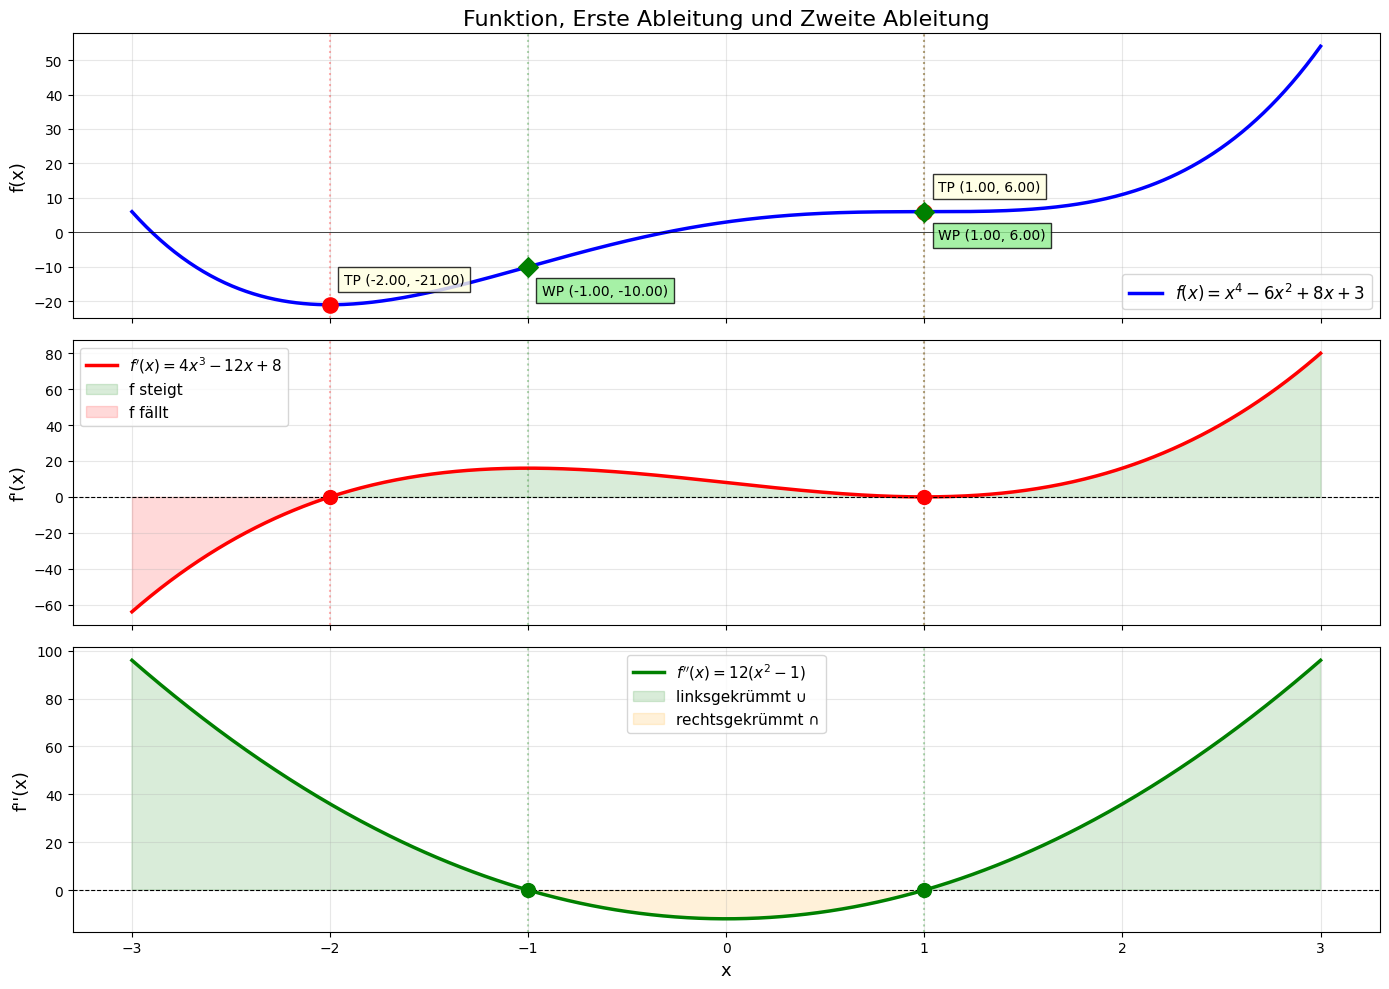

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

# --- Konfiguration ---
Ableitungen_Vergleich_Config = {
    "funktion_sym": "x**4 - 6*x**2 + 8*x + 3",
    "x_bereich": (-3, 3),
    "figsize": (14, 10),
}

def visualisiere_ableitungen_vergleich(config):
    """Zeichnet f, f' und f'' übereinander mit markierten Nullstellen."""
    x = sp.Symbol('x')
    f_sym = sp.sympify(config["funktion_sym"])
    f1_sym = sp.diff(f_sym, x)
    f2_sym = sp.diff(f_sym, x, 2)

    # In numerische Funktionen umwandeln
    f = sp.lambdify(x, f_sym, 'numpy')
    f1 = sp.lambdify(x, f1_sym, 'numpy')
    f2 = sp.lambdify(x, f2_sym, 'numpy')

    x_vals = np.linspace(*config["x_bereich"], 500)

    fig, axes = plt.subplots(3, 1, figsize=config["figsize"], sharex=True)

    # --- Panel 1: f(x) ---
    axes[0].plot(x_vals, f(x_vals), color='blue', linewidth=2.5, label=f"$f(x) = {sp.latex(f_sym)}$")
    axes[0].set_ylabel("f(x)", fontsize=13)
    axes[0].set_title("Funktion, Erste Ableitung und Zweite Ableitung", fontsize=16)
    axes[0].axhline(0, color='black', linewidth=0.5)
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(fontsize=12)

    # Extremstellen markieren (wo f'=0)
    nullstellen_f1 = sp.solve(f1_sym, x)
    for ns in nullstellen_f1:
        ns_float = float(ns)
        if config["x_bereich"][0] <= ns_float <= config["x_bereich"][1]:
            y_val = float(f_sym.subs(x, ns))
            art = "HP" if float(f2_sym.subs(x, ns)) < 0 else "TP"
            axes[0].scatter(ns_float, y_val, color='red', s=120, zorder=5)
            axes[0].annotate(f"{art} ({ns_float:.2f}, {y_val:.2f})",
                           xy=(ns_float, y_val), xytext=(10, 15),
                           textcoords='offset points', fontsize=10,
                           bbox=dict(facecolor='lightyellow', alpha=0.8))

    # --- Panel 2: f'(x) ---
    axes[1].plot(x_vals, f1(x_vals), color='red', linewidth=2.5, label=f"$f'(x) = {sp.latex(f1_sym)}$")
    axes[1].set_ylabel("f'(x)", fontsize=13)
    axes[1].axhline(0, color='black', linewidth=0.8, linestyle='--')
    axes[1].grid(True, alpha=0.3)
    axes[1].legend(fontsize=12)

    # Nullstellen von f' markieren
    for ns in nullstellen_f1:
        ns_float = float(ns)
        if config["x_bereich"][0] <= ns_float <= config["x_bereich"][1]:
            axes[1].scatter(ns_float, 0, color='red', s=100, zorder=5)
            axes[1].axvline(ns_float, color='red', alpha=0.3, linestyle=':')
            axes[0].axvline(ns_float, color='red', alpha=0.3, linestyle=':')

    # Einfärben: wo f steigt (f'>0) und wo f fällt (f'<0)
    f1_vals = f1(x_vals)
    axes[1].fill_between(x_vals, 0, f1_vals, where=(f1_vals > 0), color='green', alpha=0.15, label="f steigt")
    axes[1].fill_between(x_vals, 0, f1_vals, where=(f1_vals < 0), color='red', alpha=0.15, label="f fällt")
    axes[1].legend(fontsize=11)

    # --- Panel 3: f''(x) ---
    axes[2].plot(x_vals, f2(x_vals), color='green', linewidth=2.5, label=f"$f''(x) = {sp.latex(f2_sym)}$")
    axes[2].set_ylabel("f''(x)", fontsize=13)
    axes[2].set_xlabel("x", fontsize=13)
    axes[2].axhline(0, color='black', linewidth=0.8, linestyle='--')
    axes[2].grid(True, alpha=0.3)
    axes[2].legend(fontsize=12)

    # Wendepunkte markieren (wo f''=0)
    nullstellen_f2 = sp.solve(f2_sym, x)
    for ns in nullstellen_f2:
        ns_float = float(ns)
        if config["x_bereich"][0] <= ns_float <= config["x_bereich"][1]:
            axes[2].scatter(ns_float, 0, color='green', s=100, zorder=5)
            for ax in axes:
                ax.axvline(ns_float, color='green', alpha=0.3, linestyle=':')
            # Wendepunkt in f markieren
            y_val = float(f_sym.subs(x, ns))
            axes[0].scatter(ns_float, y_val, color='green', s=100, zorder=5, marker='D')
            axes[0].annotate(f"WP ({ns_float:.2f}, {y_val:.2f})",
                           xy=(ns_float, y_val), xytext=(10, -20),
                           textcoords='offset points', fontsize=10,
                           bbox=dict(facecolor='lightgreen', alpha=0.8))

    # Einfärben: Krümmung
    f2_vals = f2(x_vals)
    axes[2].fill_between(x_vals, 0, f2_vals, where=(f2_vals > 0), color='green', alpha=0.15, label="linksgekrümmt ∪")
    axes[2].fill_between(x_vals, 0, f2_vals, where=(f2_vals < 0), color='orange', alpha=0.15, label="rechtsgekrümmt ∩")
    axes[2].legend(fontsize=11)

    plt.tight_layout()
    plt.show()

visualisiere_ableitungen_vergleich(Ableitungen_Vergleich_Config)

### 3. Extremstellen bestimmen

Um Hoch- und Tiefpunkte systematisch zu finden, gehst Du in zwei Schritten vor:

**Schritt 1: Notwendige Bedingung** - Setze $f'(x) = 0$ und löse nach $x$.
Die Lösungen sind die **Kandidaten** für Extremstellen.

**Schritt 2: Hinreichende Bedingung** - Prüfe mit der zweiten Ableitung, ob es sich um ein Maximum oder Minimum handelt:
- $f''(x_0) < 0 \Rightarrow$ **Hochpunkt** (Maximum) - die Kurve ist rechtsgekrümmt ∩
- $f''(x_0) > 0 \Rightarrow$ **Tiefpunkt** (Minimum) - die Kurve ist linksgekrümmt ∪
- $f''(x_0) = 0 \Rightarrow$ Keine Aussage! Könnte ein **Sattelpunkt** sein (→ höhere Ableitungen prüfen)

#### Was ist ein Sattelpunkt?
Ein **Sattelpunkt** (auch Terrassenpunkt) ist eine Stelle, an der $f'(x_0) = 0$ und $f''(x_0) = 0$ gilt, aber **kein Extremum** vorliegt. Die Funktion hat dort einen horizontalen Wendepunkt - sie „ruht" kurz und setzt dann in derselben Richtung fort.

**Beispiel:** $f(x) = x^3$ bei $x = 0$:
- $f'(x) = 3x^2 \Rightarrow f'(0) = 0$ ✓
- $f''(x) = 6x \Rightarrow f''(0) = 0$ - keine Aussage!
- $f'''(x) = 6 \Rightarrow f'''(0) = 6 \neq 0$ → Wendepunkt (Sattelpunkt)

In [3]:
import sympy as sp

x = sp.Symbol('x')

# --- Extremstellen bestimmen für f(x) = x⁴ - 6x² + 8x + 3 ---
f = x**4 - 6*x**2 + 8*x + 3
f1 = sp.diff(f, x)
f2 = sp.diff(f, x, 2)

print(f"f(x)   = {f}")
print(f"f'(x)  = {f1}")
print(f"f''(x) = {f2}")
print()

# Schritt 1: f'(x) = 0 lösen
kritische_stellen = sp.solve(f1, x)
print(f"Kritische Stellen (f'(x)=0): {kritische_stellen}")
print()

# Schritt 2: Hinreichende Bedingung prüfen
for x0 in kritische_stellen:
    f2_wert = f2.subs(x, x0)
    f_wert = f.subs(x, x0)
    if f2_wert < 0:
        art = "HOCHPUNKT (Maximum)"
    elif f2_wert > 0:
        art = "TIEFPUNKT (Minimum)"
    else:
        art = "KEINE AUSSAGE (evtl. Sattelpunkt)"
    print(f"x₀ = {x0:.4f}: f(x₀) = {float(f_wert):.4f}, f''(x₀) = {float(f2_wert):.4f} → {art}")

print()
print("--- Sattelpunkt-Beispiel: f(x) = x³ ---")
g = x**3
g1 = sp.diff(g, x)
g2 = sp.diff(g, x, 2)
g3 = sp.diff(g, x, 3)
print(f"f'(0)  = {g1.subs(x, 0)}")
print(f"f''(0) = {g2.subs(x, 0)} → keine Aussage!")
print(f"f'''(0)= {g3.subs(x, 0)} ≠ 0 → Sattelpunkt")

f(x)   = x**4 - 6*x**2 + 8*x + 3
f'(x)  = 4*x**3 - 12*x + 8
f''(x) = 12*(x**2 - 1)

Kritische Stellen (f'(x)=0): [-2, 1]

x₀ = -2.0000: f(x₀) = -21.0000, f''(x₀) = 36.0000 → TIEFPUNKT (Minimum)
x₀ = 1.0000: f(x₀) = 6.0000, f''(x₀) = 0.0000 → KEINE AUSSAGE (evtl. Sattelpunkt)

--- Sattelpunkt-Beispiel: f(x) = x³ ---
f'(0)  = 0
f''(0) = 0 → keine Aussage!
f'''(0)= 6 ≠ 0 → Sattelpunkt


### 4. Wendepunkte bestimmen

Ein **Wendepunkt** ist eine Stelle, an der die Krümmung der Kurve wechselt (von linksgekrümmt zu rechtsgekrümmt oder umgekehrt).

**Schritt 1: Notwendige Bedingung** - Setze $f''(x) = 0$ und löse nach $x$.

**Schritt 2: Hinreichende Bedingung** - Prüfe, ob die Krümmung tatsächlich wechselt:
- $f'''(x_0) \neq 0 \Rightarrow$ **Wendepunkt bestätigt**
- $f'''(x_0) = 0 \Rightarrow$ Keine Aussage (noch höhere Ableitung prüfen)

*Alternativ kannst Du auch einen Vorzeichenwechsel von $f''$ links und rechts der Stelle prüfen.*

---

### 5. Vollständige Kurvendiskussion - Schritt für Schritt

Eine **Kurvendiskussion** ist die systematische Analyse einer Funktion. Hier ist der Ablauf:

| Schritt | Was? | Wie? |
|---------|------|------|
| 1 | **Definitionsbereich** | Wo ist $f(x)$ definiert? |
| 2 | **Symmetrie** | Achsensymmetrie ($f(-x)=f(x)$)? Punktsymmetrie ($f(-x)=-f(x)$)? |
| 3 | **Nullstellen** | Löse $f(x) = 0$ |
| 4 | **Extremstellen** | $f'(x) = 0$ lösen, $f''$ prüfen |
| 5 | **Wendepunkte** | $f''(x) = 0$ lösen, $f'''$ prüfen |
| 6 | **Monotonieverhalten** | Wo ist $f'(x) > 0$ (steigend) bzw. $< 0$ (fallend)? |
| 7 | **Krümmungsverhalten** | Wo ist $f''(x) > 0$ (linksgekr.) bzw. $< 0$ (rechtsgekr.)? |
| 8 | **Verhalten im Unendlichen** | $\lim_{x \to \pm\infty} f(x)$ |
| 9 | **Graph zeichnen** | Alles zusammenführen |

Lass uns das komplett durchführen:

In [4]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

x = sp.Symbol('x')

# === VOLLSTÄNDIGE KURVENDISKUSSION ===
# Funktion: f(x) = x³ - 3x² - 9x + 27

f_sym = x**3 - 3*x**2 - 9*x + 27
f1_sym = sp.diff(f_sym, x)
f2_sym = sp.diff(f_sym, x, 2)
f3_sym = sp.diff(f_sym, x, 3)

print("=" * 60)
print("KURVENDISKUSSION: f(x) = x³ - 3x² - 9x + 27")
print("=" * 60)

# 1. Definitionsbereich
print("\n1. DEFINITIONSBEREICH")
print("   D = ℝ (Polynom → überall definiert)")

# 2. Symmetrie
print("\n2. SYMMETRIE")
f_neg = f_sym.subs(x, -x)
if sp.simplify(f_neg - f_sym) == 0:
    print("   Achsensymmetrisch (f(-x) = f(x))")
elif sp.simplify(f_neg + f_sym) == 0:
    print("   Punktsymmetrisch (f(-x) = -f(x))")
else:
    print("   Keine Symmetrie")

# 3. Nullstellen
print("\n3. NULLSTELLEN")
nullstellen = sp.solve(f_sym, x)
for ns in nullstellen:
    print(f"   x = {ns}")

# 4. Extremstellen
print(f"\n4. EXTREMSTELLEN")
print(f"   f'(x)  = {f1_sym}")
kritische = sp.solve(f1_sym, x)
for x0 in kritische:
    f2_wert = f2_sym.subs(x, x0)
    y0 = f_sym.subs(x, x0)
    if f2_wert < 0:
        art = "Hochpunkt"
    elif f2_wert > 0:
        art = "Tiefpunkt"
    else:
        art = "Sattelpunkt"
    print(f"   x₀ = {x0}: f(x₀) = {y0}, f''(x₀) = {f2_wert} → {art} ({x0}, {y0})")

# 5. Wendepunkte
print(f"\n5. WENDEPUNKTE")
print(f"   f''(x) = {f2_sym}")
wendepunkte = sp.solve(f2_sym, x)
for x0 in wendepunkte:
    f3_wert = f3_sym.subs(x, x0)
    y0 = f_sym.subs(x, x0)
    if f3_wert != 0:
        print(f"   x₀ = {x0}: f(x₀) = {y0}, f'''(x₀) = {f3_wert} ≠ 0 → Wendepunkt ({x0}, {y0})")
    else:
        print(f"   x₀ = {x0}: f'''(x₀) = 0 → kein Wendepunkt")

# 6. Monotonie
print(f"\n6. MONOTONIEVERHALTEN")
print(f"   f'(x) = {f1_sym} = {sp.factor(f1_sym)}")
if len(kritische) >= 2:
    k_sorted = sorted([float(k) for k in kritische])
    print(f"   Steigend: (-∞, {k_sorted[0]}) und ({k_sorted[1]}, +∞)")
    print(f"   Fallend:  ({k_sorted[0]}, {k_sorted[1]})")

# 7. Krümmung
print(f"\n7. KRÜMMUNGSVERHALTEN")
if len(wendepunkte) >= 1:
    wp = float(wendepunkte[0])
    print(f"   Rechtsgekrümmt (∩): (-∞, {wp})")
    print(f"   Linksgekrümmt  (∪): ({wp}, +∞)")

# 8. Verhalten im Unendlichen
print(f"\n8. VERHALTEN FÜR x → ±∞")
lim_pos = sp.limit(f_sym, x, sp.oo)
lim_neg = sp.limit(f_sym, x, -sp.oo)
print(f"   lim(x→+∞) = {lim_pos}")
print(f"   lim(x→-∞) = {lim_neg}")

# 9. Graph zeichnen
print(f"\n9. GRAPH → siehe Plot unten")

KURVENDISKUSSION: f(x) = x³ - 3x² - 9x + 27

1. DEFINITIONSBEREICH
   D = ℝ (Polynom → überall definiert)

2. SYMMETRIE
   Keine Symmetrie

3. NULLSTELLEN
   x = -3
   x = 3

4. EXTREMSTELLEN
   f'(x)  = 3*x**2 - 6*x - 9
   x₀ = -1: f(x₀) = 32, f''(x₀) = -12 → Hochpunkt (-1, 32)
   x₀ = 3: f(x₀) = 0, f''(x₀) = 12 → Tiefpunkt (3, 0)

5. WENDEPUNKTE
   f''(x) = 6*(x - 1)
   x₀ = 1: f(x₀) = 16, f'''(x₀) = 6 ≠ 0 → Wendepunkt (1, 16)

6. MONOTONIEVERHALTEN
   f'(x) = 3*x**2 - 6*x - 9 = 3*(x - 3)*(x + 1)
   Steigend: (-∞, -1.0) und (3.0, +∞)
   Fallend:  (-1.0, 3.0)

7. KRÜMMUNGSVERHALTEN
   Rechtsgekrümmt (∩): (-∞, 1.0)
   Linksgekrümmt  (∪): (1.0, +∞)

8. VERHALTEN FÜR x → ±∞
   lim(x→+∞) = oo
   lim(x→-∞) = -oo

9. GRAPH → siehe Plot unten


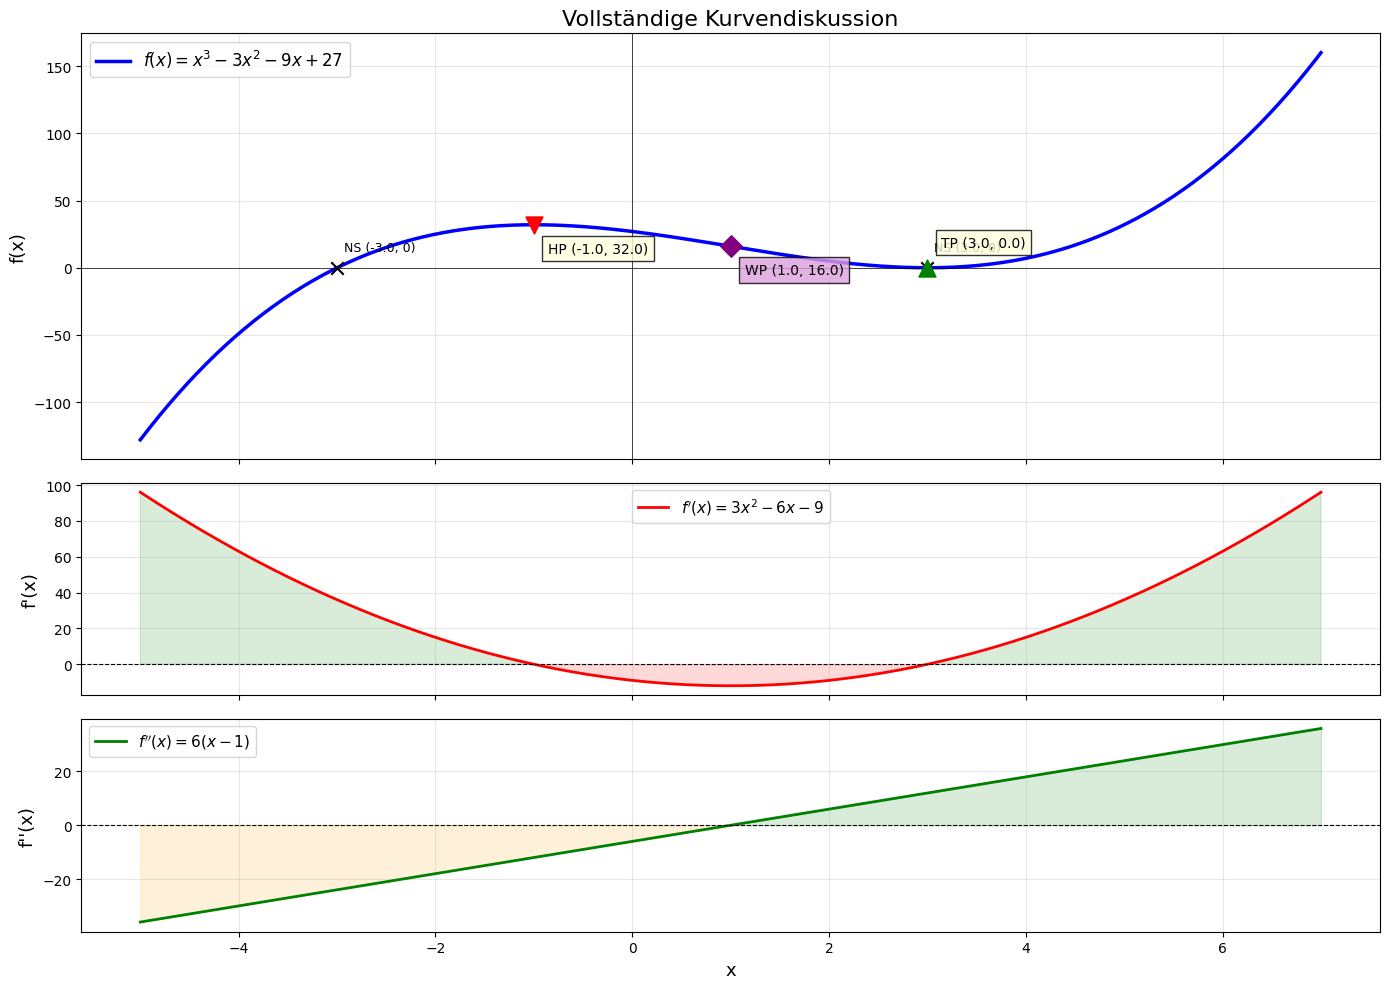

In [5]:
# --- Visualisierung der Kurvendiskussion ---

Kurvendiskussion_Config = {
    "funktion_sym": "x**3 - 3*x**2 - 9*x + 27",
    "x_bereich": (-5, 7),
    "figsize": (14, 10),
}

def visualisiere_kurvendiskussion(config):
    """Erstellt den vollständigen Graphen mit allen markanten Punkten."""
    x = sp.Symbol('x')
    f_sym = sp.sympify(config["funktion_sym"])
    f1_sym = sp.diff(f_sym, x)
    f2_sym = sp.diff(f_sym, x, 2)

    f = sp.lambdify(x, f_sym, 'numpy')
    f1 = sp.lambdify(x, f1_sym, 'numpy')
    f2 = sp.lambdify(x, f2_sym, 'numpy')

    x_vals = np.linspace(*config["x_bereich"], 500)

    fig, axes = plt.subplots(3, 1, figsize=config["figsize"], sharex=True,
                             gridspec_kw={'height_ratios': [3, 1.5, 1.5]})

    # === f(x) ===
    ax = axes[0]
    ax.plot(x_vals, f(x_vals), color='blue', linewidth=2.5, label=f"$f(x) = {sp.latex(f_sym)}$")
    ax.axhline(0, color='black', linewidth=0.5)
    ax.axvline(0, color='black', linewidth=0.5)
    ax.grid(True, alpha=0.3)
    ax.set_ylabel("f(x)", fontsize=13)
    ax.set_title("Vollständige Kurvendiskussion", fontsize=16)

    # Nullstellen
    for ns in sp.solve(f_sym, x):
        ns_f = float(ns)
        ax.scatter(ns_f, 0, color='black', s=80, zorder=5, marker='x')
        ax.annotate(f"NS ({ns_f:.1f}, 0)", xy=(ns_f, 0), xytext=(5, 12),
                   textcoords='offset points', fontsize=9)

    # Extremstellen
    for x0 in sp.solve(f1_sym, x):
        x0_f = float(x0)
        y0_f = float(f_sym.subs(x, x0))
        f2_val = float(f2_sym.subs(x, x0))
        farbe = 'red' if f2_val < 0 else 'green'
        marker_type = 'v' if f2_val < 0 else '^'
        label = "HP" if f2_val < 0 else "TP"
        ax.scatter(x0_f, y0_f, color=farbe, s=150, zorder=5, marker=marker_type)
        ax.annotate(f"{label} ({x0_f:.1f}, {y0_f:.1f})", xy=(x0_f, y0_f),
                   xytext=(10, 15 if f2_val > 0 else -20),
                   textcoords='offset points', fontsize=10,
                   bbox=dict(facecolor='lightyellow', alpha=0.8))

    # Wendepunkte
    for x0 in sp.solve(f2_sym, x):
        x0_f = float(x0)
        y0_f = float(f_sym.subs(x, x0))
        ax.scatter(x0_f, y0_f, color='purple', s=120, zorder=5, marker='D')
        ax.annotate(f"WP ({x0_f:.1f}, {y0_f:.1f})", xy=(x0_f, y0_f),
                   xytext=(10, -20), textcoords='offset points', fontsize=10,
                   bbox=dict(facecolor='plum', alpha=0.8))

    ax.legend(fontsize=12)

    # === f'(x) ===
    ax1 = axes[1]
    f1_vals = f1(x_vals)
    ax1.plot(x_vals, f1_vals, color='red', linewidth=2, label=f"$f'(x) = {sp.latex(f1_sym)}$")
    ax1.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax1.fill_between(x_vals, 0, f1_vals, where=(f1_vals > 0), color='green', alpha=0.15)
    ax1.fill_between(x_vals, 0, f1_vals, where=(f1_vals < 0), color='red', alpha=0.15)
    ax1.grid(True, alpha=0.3)
    ax1.set_ylabel("f'(x)", fontsize=13)
    ax1.legend(fontsize=11)

    # === f''(x) ===
    ax2 = axes[2]
    f2_vals = f2(x_vals)
    ax2.plot(x_vals, f2_vals, color='green', linewidth=2, label=f"$f''(x) = {sp.latex(f2_sym)}$")
    ax2.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax2.fill_between(x_vals, 0, f2_vals, where=(f2_vals > 0), color='green', alpha=0.15)
    ax2.fill_between(x_vals, 0, f2_vals, where=(f2_vals < 0), color='orange', alpha=0.15)
    ax2.grid(True, alpha=0.3)
    ax2.set_ylabel("f''(x)", fontsize=13)
    ax2.set_xlabel("x", fontsize=13)
    ax2.legend(fontsize=11)

    plt.tight_layout()
    plt.show()

visualisiere_kurvendiskussion(Kurvendiskussion_Config)

---

### Verständnis-Check
*Führe eine vollständige Kurvendiskussion auf Papier durch!*

**Aufgabe 1:** $f(x) = -x^3 + 3x + 2$

Bestimme:
- a) Ableitungen $f'(x)$ und $f''(x)$
- b) Extremstellen (Art und Koordinaten)
- c) Wendepunkte
- d) Monotonie- und Krümmungsintervalle

**Aufgabe 2:** $f(x) = x^4 - 8x^2$

Bestimme:
- a) Nullstellen
- b) Symmetrie
- c) Extremstellen
- d) Wendepunkte
- e) Skizziere den Graphen mit allen gefundenen Punkten

**Aufgabe 3:** Erkläre den Unterschied zwischen einem **Wendepunkt** und einem **Sattelpunkt**. Gib jeweils ein Beispiel einer Funktion an.

**Aufgabe 4:** Bei welcher Funktion gilt $f'(x) = 0$ und $f''(x) = 0$ bei $x=0$, aber es liegt *kein* Extremum und *kein* Wendepunkt vor?
*(Tipp: Denke an $f(x) = x^4$ - prüfe genau!)*

### Lösungen

**Lösung 1:**
- a) $f'(x) = -3x^2 + 3$, $f''(x) = -6x$
- b) $f'(x) = 0 \Rightarrow -3x^2 + 3 = 0 \Rightarrow x^2 = 1 \Rightarrow x = \pm 1$
  - $f''(-1) = 6 > 0 \Rightarrow$ Tiefpunkt $(-1, 0)$
  - $f''(1) = -6 < 0 \Rightarrow$ Hochpunkt $(1, 4)$
- c) $f''(x) = 0 \Rightarrow x = 0$, $f'''(x) = -6 \neq 0 \Rightarrow$ Wendepunkt $(0, 2)$
- d) Steigend: $(-1, 1)$, Fallend: $(-\infty, -1)$ und $(1, \infty)$.
  Linksgekrümmt: $(-\infty, 0)$, Rechtsgekrümmt: $(0, \infty)$

**Lösung 2:**
- a) $x^4 - 8x^2 = x^2(x^2 - 8) = 0 \Rightarrow x = 0, x = \pm 2\sqrt{2}$
- b) $f(-x) = (-x)^4 - 8(-x)^2 = x^4 - 8x^2 = f(x) \Rightarrow$ achsensymmetrisch
- c) $f'(x) = 4x^3 - 16x = 4x(x^2 - 4) = 0 \Rightarrow x = 0, \pm 2$
  - $f''(x) = 12x^2 - 16$; $f''(0) = -16 < 0 \Rightarrow$ HP $(0, 0)$
  - $f''(2) = 32 > 0 \Rightarrow$ TP $(2, -16)$; $f''(-2) = 32 > 0 \Rightarrow$ TP $(-2, -16)$
- d) $f''(x) = 0 \Rightarrow 12x^2 = 16 \Rightarrow x = \pm\frac{2\sqrt{3}}{3}$, WP bei $(\pm 1{,}15; -7{,}11)$

**Lösung 3:**
- **Wendepunkt:** Stelle, an der die Krümmung wechselt ($f'' = 0$ mit VZW). Bsp: $f(x) = x^3$ bei $x=0$.
- **Sattelpunkt:** Spezialfall eines Wendepunkts, bei dem *zusätzlich* $f' = 0$ gilt (horizontale Tangente). Bsp: $f(x) = x^3$ bei $x=0$.
- Jeder Sattelpunkt ist ein Wendepunkt, aber nicht umgekehrt!

**Lösung 4:** $f(x) = x^4$: $f'(0) = 0$, $f''(0) = 0$, aber $f''''(0) = 24 > 0$. Es liegt ein Tiefpunkt vor (kein Wendepunkt). Die hinreichende Bedingung $f''=0$ liefert keine Aussage - man muss höhere Ableitungen prüfen!

In [6]:
import sympy as sp

x = sp.Symbol('x')

# --- Lösungen mit SymPy überprüfen ---

aufgaben = {
    "Aufgabe 1: -x³ + 3x + 2": -x**3 + 3*x + 2,
    "Aufgabe 2: x⁴ - 8x²": x**4 - 8*x**2,
}

for name, f_sym in aufgaben.items():
    print(f"\n{'=' * 60}")
    print(f"  {name}")
    print(f"{'=' * 60}")

    f1 = sp.diff(f_sym, x)
    f2 = sp.diff(f_sym, x, 2)
    f3 = sp.diff(f_sym, x, 3)

    print(f"f(x)   = {f_sym}")
    print(f"f'(x)  = {f1}")
    print(f"f''(x) = {f2}")

    # Nullstellen
    ns = sp.solve(f_sym, x)
    print(f"\nNullstellen: {ns}")

    # Extremstellen
    krit = sp.solve(f1, x)
    print(f"\nKritische Stellen: {krit}")
    for x0 in krit:
        y0 = f_sym.subs(x, x0)
        f2_val = f2.subs(x, x0)
        art = "HP" if f2_val < 0 else ("TP" if f2_val > 0 else "?")
        print(f"  x={x0}: f={y0}, f''={f2_val} → {art}")

    # Wendepunkte
    wp = sp.solve(f2, x)
    print(f"\nWendepunkt-Kandidaten: {wp}")
    for x0 in wp:
        y0 = f_sym.subs(x, x0)
        f3_val = f3.subs(x, x0)
        print(f"  x={x0}: f={y0}, f'''={f3_val} {'→ WP' if f3_val != 0 else '→ kein WP'}")


  Aufgabe 1: -x³ + 3x + 2
f(x)   = -x**3 + 3*x + 2
f'(x)  = 3 - 3*x**2
f''(x) = -6*x

Nullstellen: [-1, 2]

Kritische Stellen: [-1, 1]
  x=-1: f=0, f''=6 → TP
  x=1: f=4, f''=-6 → HP

Wendepunkt-Kandidaten: [0]
  x=0: f=2, f'''=-6 → WP

  Aufgabe 2: x⁴ - 8x²
f(x)   = x**4 - 8*x**2
f'(x)  = 4*x**3 - 16*x
f''(x) = 4*(3*x**2 - 4)

Nullstellen: [0, -2*sqrt(2), 2*sqrt(2)]

Kritische Stellen: [-2, 0, 2]
  x=-2: f=-16, f''=32 → TP
  x=0: f=0, f''=-16 → HP
  x=2: f=-16, f''=32 → TP

Wendepunkt-Kandidaten: [-2*sqrt(3)/3, 2*sqrt(3)/3]
  x=-2*sqrt(3)/3: f=-80/9, f'''=-16*sqrt(3) → WP
  x=2*sqrt(3)/3: f=-80/9, f'''=16*sqrt(3) → WP


---

### Zusammenfassung

In diesem Abschnitt hast Du gelernt:
- **Höhere Ableitungen** ($f'', f''', \ldots$) geben Auskunft über Krümmung und deren Änderung
- **$f'$ zeigt das Steigungsverhalten:** positiv = steigend, negativ = fallend
- **$f''$ zeigt das Krümmungsverhalten:** positiv = linksgekrümmt (∪), negativ = rechtsgekrümmt (∩)
- **Extremstellen:** $f'(x_0) = 0$ (notwendig), $f''(x_0) \neq 0$ (hinreichend)
- **Wendepunkte:** $f''(x_0) = 0$ (notwendig), $f'''(x_0) \neq 0$ (hinreichend)
- **Sattelpunkt:** Wendepunkt mit horizontaler Tangente ($f' = 0$ und $f'' = 0$)
- Die **Kurvendiskussion** ist das systematische Werkzeug, um eine Funktion komplett zu analysieren

Im nächsten Schritt kannst Du Dich mit **partiellen Ableitungen** beschäftigen - Ableitungen von Funktionen mit *mehreren* Variablen.

---

### Glossar (Deutsch - Englisch)

| Deutsch | Englisch |
|---------|----------|
| Höhere Ableitung | Higher-order derivative |
| Erste / Zweite / Dritte Ableitung | First / Second / Third derivative |
| Extremstelle | Extremum (critical point) |
| Hochpunkt (Maximum) | Maximum (peak) |
| Tiefpunkt (Minimum) | Minimum (valley) |
| Sattelpunkt / Terrassenpunkt | Saddle point / Inflection with zero slope |
| Wendepunkt | Inflection point |
| Monotonieverhalten | Monotonicity |
| Krümmungsverhalten | Concavity |
| Linksgekrümmt (konkav) | Concave up |
| Rechtsgekrümmt (konvex) | Concave down |
| Kurvendiskussion | Curve sketching / Curve analysis |
| Notwendige Bedingung | Necessary condition |
| Hinreichende Bedingung | Sufficient condition |